<a href="https://colab.research.google.com/github/gguex/ISH_ressources_cours_ML/blob/main/TP08_entrainer_un_reseau.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning (Lettres) TP 8 : Entraîner un réseau de neurones

Dans ce TP, nous entraînons un perceptron multicouche avec PyTorch, en suivant pas à pas la recette du cours 8. Les données sont les vins blancs du TP 2 : il s'agit de prédire la qualité d'un vin, regroupée en trois classes, à partir de ses onze mesures chimiques. Nous comparerons plusieurs réseaux sur la validation, en observant le surapprentissage et l'effet de la régularisation, puis nous évaluerons le réseau retenu sur le test, face à une régression logistique.

Un exercice reprend la recette sur d'autres données.

Nouveautés : `TensorDataset` et `DataLoader`, une classe qui hérite de `nn.Module`, les couches `nn.Linear`, `nn.ReLU` et `nn.Dropout`, la perte `nn.CrossEntropyLoss`, l'optimiseur `torch.optim.Adam`, et la sauvegarde des paramètres avec `state_dict`.

In [1]:
from pathlib import Path
import copy

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
# PyTorch : les tenseurs, les couches des réseaux, et les outils pour les données
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
# Pour séparer et standardiser les données
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# La référence de la partie 1 : la régression logistique
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Le même style de graphiques qu'aux TP précédents
sns.set_theme(style="whitegrid", palette="colorblind")

In [2]:
# Connexion à Google Drive sur Colab ; dossier local sinon
try:
    from google.colab import drive
except ImportError:
    data_path = Path("data") / "TP8"
else:
    drive.mount("/content/drive")
    data_path = Path("/content/drive/MyDrive/Colab Notebooks/data/TP8")

Mounted at /content/drive


Comme au TP 7, `device` retient l'emplacement de calcul, et on fixe la graine de PyTorch.

In [3]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42)
print(device)

cpu


Les fonctions `compute_scores` et `plot_confusion` du TP 3 :

In [4]:
def compute_scores(outputs_true, outputs_pred, average="binary"):
    return {
        "Exactitude": accuracy_score(outputs_true, outputs_pred),
        "Précision": precision_score(outputs_true, outputs_pred,
                                     average=average, zero_division=0),
        "Rappel": recall_score(outputs_true, outputs_pred, average=average),
        "F1": f1_score(outputs_true, outputs_pred, average=average),
    }


def plot_confusion(outputs_true, outputs_pred):
    confusion = pd.crosstab(outputs_true, outputs_pred,
                            rownames=["Vraie classe"],
                            colnames=["Classe prédite"])
    fig, ax = plt.subplots(figsize=(4, 3), layout="constrained")
    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    plt.show()

---

## La recette

Le cours 8 donne une recette en huit étapes, que nous suivons dans l'ordre :

1. Séparer entraînement, validation et test ; standardiser avec l'entraînement.
2. Ranger les données dans des `DataLoader`, qui fournissent les mini-batchs.
3. Écrire la classe du réseau, qui renvoie des logits.
4. Choisir la perte et l'optimiseur.
5. À chaque epoch : `train_one_epoch`, puis `evaluate` sur la validation.
6. Tracer les courbes d'apprentissage ; garder la meilleure epoch.
7. Évaluer une seule fois sur le test.
8. Sauvegarder les paramètres du réseau.

## 1. Trois jeux de données

Les vins blancs du TP 2 ont onze mesures chimiques et une note de qualité, de 3 à 9. On regroupe les notes en trois classes avec `pd.cut` : la classe 0 pour une note de 5 ou moins, la classe 1 pour une note de 6, la classe 2 pour une note de 7 ou plus.

In [5]:
data = pd.read_csv(data_path / "winequality-white.csv", sep=";")
inputs = data.drop(columns=["quality"])
# Intervalles ]0, 5], ]5, 6] et ]6, 10] : les classes 0, 1 et 2
outputs = pd.cut(data["quality"], bins=[0, 5, 6, 10], labels=[0, 1, 2]).astype(int)
outputs.value_counts().sort_index()

,count
quality,
0,1640
1,2198
2,1060


On met d'abord 20 % des vins de côté pour le test, puis on coupe le reste en 75 % pour l'entraînement et 25 % pour la validation : soit 60 %, 20 % et 20 % du total. Les deux séparations sont stratifiées. La standardisation est apprise sur l'entraînement seulement, puis appliquée aux trois jeux.

In [6]:
inputs_dev, inputs_test, outputs_dev, outputs_test = \
    train_test_split(inputs, outputs, test_size=0.2, stratify=outputs,
                     random_state=42)
inputs_train, inputs_valid, outputs_train, outputs_valid = \
    train_test_split(inputs_dev, outputs_dev, test_size=0.25, stratify=outputs_dev,
                     random_state=42)

scaler = StandardScaler().fit(inputs_train)
inputs_train_std = scaler.transform(inputs_train)
inputs_valid_std = scaler.transform(inputs_valid)
inputs_test_std = scaler.transform(inputs_test)
print(len(inputs_train), len(inputs_valid), len(inputs_test))

2938 980 980


## 2. Les mini-batchs

PyTorch travaille sur des tenseurs : les variables en `float32`, les classes en entiers (`torch.long`), comme l'attend `nn.CrossEntropyLoss`. Un `TensorDataset` associe chaque ligne de `X` à sa classe dans `y`, et un `DataLoader` découpe ce jeu en mini-batchs de 64 vins. Seul le `DataLoader` d'entraînement mélange les vins, au début de chaque epoch. La fonction `make_loader` fait ces trois opérations :

In [7]:
def make_loader(inputs_std, outputs, shuffle):
    """Tenseurs, TensorDataset, puis DataLoader en mini-batchs de 64."""
    X = torch.tensor(inputs_std, dtype=torch.float32)
    y = torch.tensor(outputs.to_numpy(), dtype=torch.long)
    return DataLoader(TensorDataset(X, y), batch_size=64, shuffle=shuffle)


train_loader = make_loader(inputs_train_std, outputs_train, shuffle=True)
valid_loader = make_loader(inputs_valid_std, outputs_valid, shuffle=False)
test_loader = make_loader(inputs_test_std, outputs_test, shuffle=False)

Un `DataLoader` se parcourt avec une boucle `for`, un mini-batch à la fois. `next(iter(train_loader))` donne seulement le premier :

In [8]:
X_batch, y_batch = next(iter(train_loader))
print(X_batch.shape, y_batch.shape)
print(y_batch[:10])
print(f"{len(train_loader)} mini-batchs par epoch")

torch.Size([64, 11]) torch.Size([64])
tensor([0, 0, 1, 0, 0, 1, 2, 2, 1, 0])
46 mini-batchs par epoch


Un mini-batch contient 64 vins avec leurs 11 variables, et leurs 64 classes. Les 2 938 vins d'entraînement donnent $\lceil 2938 / 64 \rceil = 46$ mini-batchs, donc 46 itérations par epoch (cours 8).

## 3. Le réseau

C'est la classe du cours 8 : `__init__` déclare les couches, `forward` décrit le passage avant. Le taux de dropout est un argument, pour pouvoir le changer plus loin. Le réseau renvoie un logit par classe.

In [9]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_classes, dropout=0.2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(n_hidden, n_classes))       # renvoie des logits

    def forward(self, x):
        return self.layers(x)

In [10]:
n_inputs = X_batch.shape[1]       # les 11 variables
model = MLP(n_inputs=n_inputs, n_hidden=64, n_classes=3).to(device)
print(model)
n_parameters = sum(parameter.numel() for parameter in model.parameters())
print(f"{n_parameters} paramètres")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=11, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=3, bias=True)
  )
)
5123 paramètres


Le réseau a $(11 \times 64 + 64) + (64 \times 64 + 64) + (64 \times 3 + 3) = 5\,123$ paramètres, pour 2 938 vins d'entraînement. Passons notre premier mini-batch dans le réseau : on obtient 3 logits par vin, que `torch.softmax` transforme en probabilités.

In [11]:
logits = model(X_batch.to(device))
print(logits.shape)
print(torch.softmax(logits[:3], dim=1))     # les probabilités des trois premiers vins

torch.Size([64, 3])
tensor([[0.3341, 0.2969, 0.3690],
        [0.3580, 0.2780, 0.3640],
        [0.3799, 0.2707, 0.3494]], grad_fn=<SoftmaxBackward0>)


Avant l'entraînement, les probabilités restent proches de 1/3 : le réseau n'a encore rien appris.

## 4. La perte et l'optimiseur

L'entropie croisée, et l'optimiseur Adam avec les réglages du cours : un taux d'apprentissage de 0.001 et une pénalité L2 de 0.0001. L'optimiseur reçoit tous les paramètres du réseau.

In [12]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

## 5 et 6. L'entraînement et la meilleure epoch

`train_one_epoch` parcourt tous les mini-batchs d'entraînement, avec les quatre étapes du cours. La perte de chaque mini-batch est pondérée par sa taille, car le dernier est plus petit : on obtient ainsi la perte moyenne exacte de l'epoch. `evaluate` calcule la perte moyenne d'un jeu sans suivre les gradients, et renvoie aussi les classes prédites, celles de plus grand logit. `model.train()` et `model.eval()` activent et désactivent le dropout.

In [13]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    """Entraîne le réseau sur tous les mini-batchs ; renvoie la perte moyenne."""
    model.train()                                  # active le dropout
    total_loss = 0.0
    for X, y in loader:
        X, y = X.to(device), y.to(device)
        logits = model(X)              # 1. passage avant
        loss = loss_fn(logits, y)      # 2. perte
        loss.backward()                # 3. gradients
        optimizer.step()               # 4. mise à jour
        optimizer.zero_grad()          # remise à zéro des gradients
        total_loss += loss.item() * len(y)         # pondérée par la taille du mini-batch
    return total_loss / len(loader.dataset)


def evaluate(model, loader, loss_fn):
    """Renvoie la perte moyenne et les classes prédites, sans suivre les gradients."""
    model.eval()                                   # désactive le dropout
    total_loss = 0.0
    predictions = []
    with torch.no_grad():
        for X, y in loader:
            X, y = X.to(device), y.to(device)
            logits = model(X)
            total_loss += loss_fn(logits, y).item() * len(y)
            predictions.append(logits.argmax(dim=1).cpu())
    return total_loss / len(loader.dataset), torch.cat(predictions).numpy()

Voici la boucle des epochs. À chaque epoch, on entraîne, puis on évalue sur la validation ; les pertes sont gardées dans la liste `history`. Quand la perte de validation atteint un nouveau minimum, on copie les paramètres du réseau avec `copy.deepcopy` : une simple affectation suivrait la suite de l'entraînement. À la fin, on recharge les paramètres de la meilleure epoch.

In [14]:
n_epochs = 100
history = []
best_valid_loss = float("inf")

for epoch in range(1, n_epochs + 1):
    train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
    valid_loss, _ = evaluate(model, valid_loader, loss_fn)
    history.append({"epoch": epoch, "Entraînement": train_loss, "Validation": valid_loss})
    if valid_loss < best_valid_loss:                  # nouvelle meilleure epoch
        best_valid_loss = valid_loss
        best_state = copy.deepcopy(model.state_dict())

model.load_state_dict(best_state)                     # on reprend la meilleure epoch
history = pd.DataFrame(history).set_index("epoch")
history.tail()

,Entraînement,Validation
epoch,,
96,0.724009,0.775867
97,0.729419,0.774523
98,0.731115,0.773132
99,0.725939,0.774403
100,0.718012,0.777601


La fonction `plot_history` trace les courbes d'apprentissage, avec la meilleure epoch en pointillés. Elle resservira :

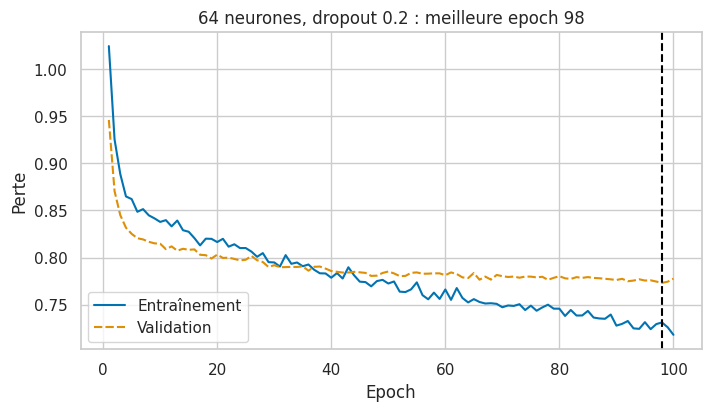

In [15]:
def plot_history(history, title):
    """Courbes d'apprentissage, avec la meilleure epoch en pointillés."""
    best_epoch = history["Validation"].idxmin()
    fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
    sns.lineplot(data=history, ax=ax)
    ax.axvline(best_epoch, color="black", linestyle="--")
    ax.set(xlabel="Epoch", ylabel="Perte",
           title=f"{title} : meilleure epoch {best_epoch}")
    plt.show()


plot_history(history, "64 neurones, dropout 0.2")

Les deux pertes baissent vite pendant une dizaine d'epochs. Ensuite, la perte d'entraînement continue de baisser, alors que la perte de validation se stabilise vers 0.78 : le réseau commence à apprendre des particularités du jeu d'entraînement, sans que la validation se dégrade. La meilleure epoch, 98, est presque la dernière.

## Choisir un réseau sur la validation

Pour comparer plusieurs réseaux, on range la boucle des epochs dans une fonction, `train_model`. Elle renvoie les pertes de chaque epoch, et laisse dans le réseau les paramètres de sa meilleure epoch.

In [16]:
def train_model(model, train_loader, valid_loader, loss_fn, optimizer, n_epochs):
    """Entraîne le réseau et garde les paramètres de la meilleure epoch.
    Renvoie les pertes de chaque epoch dans un DataFrame."""
    history = []
    best_valid_loss = float("inf")
    for epoch in range(1, n_epochs + 1):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        valid_loss, _ = evaluate(model, valid_loader, loss_fn)
        history.append({"epoch": epoch, "Entraînement": train_loss, "Validation": valid_loss})
        if valid_loss < best_valid_loss:
            best_valid_loss = valid_loss
            best_state = copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state)
    return pd.DataFrame(history).set_index("epoch")

Un réseau beaucoup plus grand, avec 256 neurones par couche cachée, sans dropout ni pénalité L2 : il compte près de 70 000 paramètres pour 2 938 vins. On fixe la même graine avant chaque réseau, pour comparer à conditions égales.

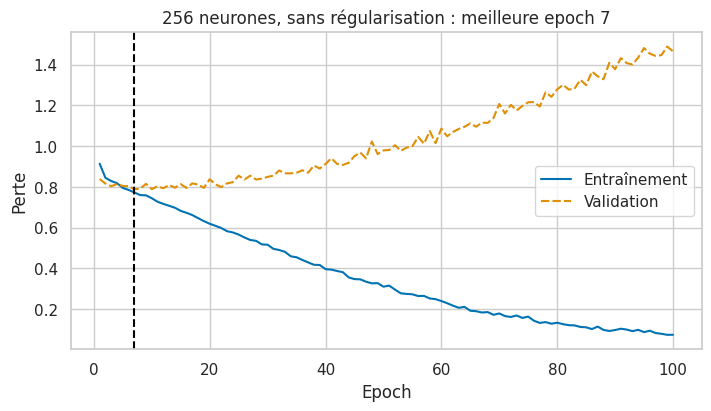

In [17]:
torch.manual_seed(42)
big_model = MLP(n_inputs=n_inputs, n_hidden=256, n_classes=3, dropout=0.0).to(device)
big_optimizer = torch.optim.Adam(big_model.parameters(), lr=0.001)
big_history = train_model(big_model, train_loader, valid_loader, loss_fn, big_optimizer,
                          n_epochs=100)
plot_history(big_history, "256 neurones, sans régularisation")

Voici le surapprentissage du cours. La perte d'entraînement descend presque à zéro : le réseau apprend les vins d'entraînement par cœur. La perte de validation, elle, remonte dès la 7e epoch, jusqu'à près du double de son minimum. Grâce à la meilleure epoch, `big_model` garde pourtant les paramètres de l'epoch 7 : c'est l'arrêt prématuré.

Le même réseau, avec un dropout de 0.3 et une pénalité L2 de 0.001 :

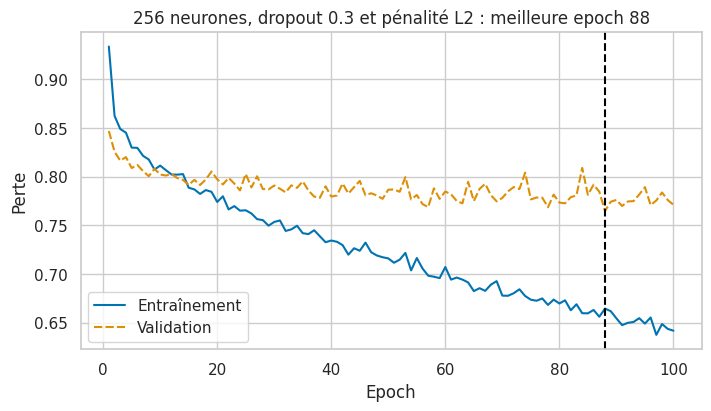

In [18]:
torch.manual_seed(42)
reg_model = MLP(n_inputs=n_inputs, n_hidden=256, n_classes=3, dropout=0.3).to(device)
reg_optimizer = torch.optim.Adam(reg_model.parameters(), lr=0.001, weight_decay=1e-3)
reg_history = train_model(reg_model, train_loader, valid_loader, loss_fn, reg_optimizer,
                          n_epochs=100)
plot_history(reg_history, "256 neurones, dropout 0.3 et pénalité L2")

Avec la régularisation, la perte d'entraînement baisse beaucoup plus lentement, et la perte de validation ne remonte plus : elle reste autour de 0.78 jusqu'à la fin. Le dropout et la pénalité L2 ont freiné l'apprentissage par cœur.

Comparons les trois réseaux sur la validation, chacun avec les paramètres de sa meilleure epoch. Le F1 macro est notre mesure principale, comme dans la partie 1.

In [19]:
networks = {"64 neurones, dropout 0.2": model,
            "256 neurones, sans régularisation": big_model,
            "256 neurones, dropout 0.3 et pénalité L2": reg_model}
valid_scores = {}
for name, network in networks.items():
    valid_loss, outputs_valid_pred = evaluate(network, valid_loader, loss_fn)
    valid_scores[name] = {"Perte de validation": valid_loss,
                          "F1 macro de validation": f1_score(outputs_valid, outputs_valid_pred,
                                                             average="macro")}
pd.DataFrame(valid_scores).T.round(3)

,Perte de validation,F1 macro de validation
"64 neurones, dropout 0.2",0.773,0.621
"256 neurones, sans régularisation",0.788,0.603
"256 neurones, dropout 0.3 et pénalité L2",0.765,0.626


Le grand réseau sans régularisation est le moins bon. Les deux autres sont à égalité, avec 0.623 et 0.620 de F1 macro : un écart trop petit pour les départager. À performances égales, on préfère le réseau le plus simple, celui du cours, avec 5 123 paramètres au lieu de près de 70 000. C'est `model`, déjà ramené à sa meilleure epoch.

In [20]:
chosen_model = model

## 7. Le test

Le test n'a servi à aucun choix. On l'utilise maintenant, une seule fois, pour le réseau retenu et pour la référence de la partie 1 : une régression logistique, avec ses réglages par défaut.

In [21]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(inputs_train_std, outputs_train)
outputs_log_test = log_reg.predict(inputs_test_std)

_, outputs_mlp_test = evaluate(chosen_model, test_loader, loss_fn)

pd.DataFrame({"Régression logistique": compute_scores(outputs_test, outputs_log_test,
                                                      average="macro"),
              "Perceptron multicouche": compute_scores(outputs_test, outputs_mlp_test,
                                                       average="macro")}).T.round(3)

,Exactitude,Précision,Rappel,F1
Régression logistique,0.595,0.615,0.560,0.575
Perceptron multicouche,0.604,0.615,0.588,0.598


Le perceptron multicouche fait mieux que la régression logistique sur le test : 0.600 contre 0.575 de F1 macro. Le gain reste modeste : la qualité d'un vin, une note de dégustation, ne se lit qu'en partie dans ses mesures chimiques.

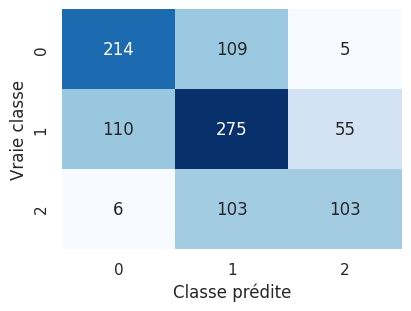

In [22]:
plot_confusion(outputs_test, outputs_mlp_test)

Presque toutes les erreurs confondent des classes voisines : une note de 5 ou moins avec une note de 6, ou une note de 6 avec une note de 7 ou plus. Le réseau ne confond que 12 fois les deux classes extrêmes. Près de la moitié des bons vins, 103 sur 212, sont classés dans la classe du milieu.

## 8. La sauvegarde

On sauvegarde les paramètres du réseau (`state_dict`), pas le réseau entier. Pour les recharger, on recrée un réseau de même architecture, puis on y charge les paramètres. Les prédictions du réseau rechargé doivent être identiques.

In [23]:
weights_path = data_path / "mlp_vins.pt"
torch.save(chosen_model.state_dict(), weights_path)

loaded_model = MLP(n_inputs=n_inputs, n_hidden=64, n_classes=3).to(device)
loaded_model.load_state_dict(torch.load(weights_path, weights_only=True))
_, outputs_loaded_test = evaluate(loaded_model, test_loader, loss_fn)
print((outputs_loaded_test == outputs_mlp_test).all())

True


La semaine prochaine, la même recette servira à des réseaux à convolution, sur des images.

---

## Exercice

Le fichier "contraceptive.tsv" (séparateur : tabulation) décrit 1 473 femmes mariées interrogées en Indonésie en 1987 : âge, niveau d'éducation de la femme et du mari, nombre d'enfants, religion, emploi, profession du mari, niveau de vie, exposition aux médias. La variable `target` donne la méthode de contraception utilisée : 1 pour aucune, 2 pour une méthode de longue durée, 3 pour une méthode de courte durée. Les autres variables sont codées par des nombres, que l'on utilise tels quels. Il vous faut :

1. Charger les données, coder la sortie en 0, 1 et 2, séparer entraînement, validation et test (60 %, 20 % et 20 %, stratifié, `random_state=42`), et standardiser.
2. Créer les trois `DataLoader` avec `make_loader`.
3. Entraîner le réseau du cours (64 neurones, dropout 0.2, pénalité L2 de 0.0001) pendant 100 epochs avec `train_model`, et tracer ses courbes. À partir de quelle epoch le réseau surapprend-il ?
4. Entraîner un réseau de 256 neurones sans régularisation, puis avec un dropout de 0.3 et une pénalité L2 de 0.001. Comparer les courbes et les mesures de validation des trois réseaux, et en choisir un.
5. Évaluer le réseau choisi et une régression logistique sur le test. Le réseau fait-il mieux ?
6. Sauvegarder le réseau choisi, le recharger, et vérifier que ses prédictions sont identiques.

In [24]:
data = pd.read_csv(data_path / "contraceptive.tsv", sep="\t")
data.head()

,Wife_age,Wife_education,Husband_education,Children,Wife_religion,Wife_working,Husband_occupation,Standard-of-living,Media_exposure,target
0,24,2,3,3,1,1,2,3,0,1
1,45,1,3,10,1,1,3,4,0,1
2,43,2,3,7,1,1,3,4,0,1
3,42,3,2,9,1,1,3,3,0,1
4,36,3,3,8,1,1,3,2,0,1
